<p style="text-align:center"><img src="../../../Images/Banner/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# DevOps for Geospatial Pipelines: Packaging, Testing, CI, Containers and Schedules

A notebook answers a question once. A monitoring service answers it again every few days, for
years, on machines you do not watch. Getting there takes the practices of **DevOps**: code in a
package, automated tests, checks that run on every change (continuous integration), a container
that runs the same everywhere, a schedule, configuration outside the code, logs you can query, and
versioned outputs.

This notebook applies them to a small but real pipeline, **`haor_monitor`**, in the `haor_monitor/`
folder next to it. Every few days the pipeline looks for new Sentinel-2 overpasses of **Tanguar
Haor**, a Ramsar wetland in Sunamganj, Bangladesh, and records how much of the haor is open water and
how green its land is. The notebook runs every practice for real: linting, tests with coverage, a
deliberately broken change that the tests catch, git history, the CI workflow's steps, container
checks, and the pipeline itself on a simulated schedule against Planetary Computer.



### Learning objectives

1. Structure a geospatial pipeline as a package: pure processing functions, input/output at the edges, configuration from the environment.
2. Write fast tests that need no network, and enforce lint, formatting and coverage as quality gates.
3. Use git and a CI workflow (GitHub Actions) so that every change is checked the same way.
4. Package the pipeline as a container image with good practices.
5. Make scheduled jobs idempotent and observable: incremental runs, structured logs, exit codes, versioned outputs.



### Data

| Data | Source |
|---|---|
| Sentinel-2 L2A over Tanguar Haor, 2024 | Planetary Computer STAC (read by the pipeline) |
| The pipeline project | `haor_monitor/` next to this notebook (package, tests, Dockerfile, workflows) |

Install the tools with `pip install pytest pytest-cov ruff pystac-client planetary-computer odc-stac`.
Docker is optional: Section 7 builds the image only where Docker is installed.



### Contents

1. Setup
2. DevOps in one page
3. The project
4. Quality gates: lint, format, tests, coverage
5. A broken change, caught
6. Version control and the CI workflow
7. Containers
8. Scheduled, idempotent runs
9. Observability and versioned outputs
10. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README. It also uses `pyyaml`, which no GeoLattice option installs: `pip install pyyaml`.

In [1]:
# Imports, paths, and a small helper to run shell commands from the notebook
%matplotlib inline
import json
import os
import re
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import Code, display

import geolattice

plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
WEB = DATA / "00_shared" / "data_web_cloud_gis"
PROJECT = Path("haor_monitor").resolve()                 # the project as shipped with the tutorial
OUT = (WEB / "08_10_outputs").resolve()
# Fresh output directory; pin git identity for local demo commits only
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True)
PY = sys.executable
GIT = ["git", "-c", "user.name=GeoLattice tutorial", "-c", "user.email=tutorial@example.org", "-c", "init.defaultBranch=main"]

def sh(cmd, cwd=PROJECT, env=None, check=False):
    "Run a command, return (exit code, seconds, output)."
    t0 = time.perf_counter()
    base = {k: v for k, v in os.environ.items() if k not in ("FORCE_COLOR", "CLICOLOR_FORCE")}
    p = subprocess.run(cmd, cwd=cwd, env={**base, "NO_COLOR": "1", "PY_COLORS": "0", **(env or {})},
                       capture_output=True, text=True)
    return p.returncode, time.perf_counter() - t0, (p.stdout + p.stderr).strip()

# Check that the local toolchain is available
tools = {name: sh(cmd)[2].splitlines()[0] for name, cmd in
         {"python": [PY, "--version"], "ruff": [PY, "-m", "ruff", "--version"], "pytest": [PY, "-m", "pytest", "--version"],
          "git": ["git", "--version"]}.items()}
tools["docker"] = shutil.which("docker") or "not installed"
print("geolattice", geolattice.__version__); print(json.dumps(tools, indent=1))


geolattice 0.3.11
{
 "python": "Python 3.11.16",
 "ruff": "ruff 0.16.9",
 "pytest": "pytest 9.1.1",
 "git": "git version 2.53.0",
 "docker": "not installed"
}


## DevOps in one page

| Practice | Why | In `haor_monitor` |
|---|---|---|
| **Package the code** | Importable, installable, versioned | `pyproject.toml`, `src/haor_monitor/`, a CLI (`python -m haor_monitor`) |
| **Separate logic from input/output** | Logic can be tested without data or network | `process.py` (pure), `stac.py` (network), `pipeline.py` (orchestration) |
| **Automated tests** | Changes do not silently break results | `tests/`: synthetic scenes and a fake catalogue; no network |
| **Quality gates** | Consistent code, enforced by machines | `ruff check`, `ruff format --check`, coverage ≥ 80 % |
| **Version control** | Every change is recorded and reviewable | git; pull requests |
| **Continuous integration** | The same checks on every change, on a clean machine | `.github/workflows/ci.yml` |
| **Containers** | The same environment everywhere | `Dockerfile` |
| **Scheduling** | Runs without a person | `.github/workflows/monitor.yml` (cron), or cron / Cloud Scheduler / Airflow / Prefect |
| **Configuration and secrets outside code** | One build, many environments; no keys in git | `HAOR_*` environment variables; secrets in the CI secret store |
| **Idempotent, observable jobs** | Safe retries; problems are visible | skip processed dates; JSON-lines logs; non-zero exit on failure |
| **Versioned outputs** | Know what changed, when, and roll back | results committed to a `data` branch |

## The project

In [2]:
# Inventory project files by role (package, tests, CI, other)
def tree(root, skip=("__pycache__", ".pytest_cache", ".ruff_cache", "monitor_data", ".git")):
    lines = []
    for path in sorted(root.rglob("*")):
        if any(part in skip for part in path.relative_to(root).parts) or path.is_dir():
            continue
        rel = path.relative_to(root)
        n = len(path.read_text().splitlines())
        lines.append({"file": str(rel), "lines": n, "role": {
            "src": "package", "tests": "tests", ".github": "CI / schedule"}.get(rel.parts[0], "project")})
    return pd.DataFrame(lines)

files = tree(PROJECT)
display(files.groupby("role").lines.agg(["count", "sum"]).rename(columns={"count": "files", "sum": "lines"}))
files


,files,lines
role,,
CI / schedule,2,87
package,6,342
project,4,92
tests,4,190


,file,lines,role
0,.dockerignore,8,project
1,.github/workflows/ci.yml,39,CI / schedule
2,.github/workflows/monitor.yml,48,CI / schedule
3,Dockerfile,21,project
4,README.md,24,project
5,pyproject.toml,39,project
6,src/haor_monitor/__init__.py,3,package
7,src/haor_monitor/__main__.py,45,package
8,src/haor_monitor/config.py,39,package
9,src/haor_monitor/pipeline.py,138,package


In [3]:
# Show the processing module that turns scenes into observations
display(Code(filename=str(PROJECT / "src/haor_monitor/process.py"), language="python"))


"""Pure functions that turn one day's Sentinel-2 bands into statistics. No input/output: easy to test."""

from __future__ import annotations

import math

import numpy as np

CLEAR_CLASSES = (4, 5, 6)  # SCL: vegetation, bare soil, water
EXPECTED = {"clear_fraction": (0.0, 1.0), "water_fraction": (0.0, 1.0), "ndvi_land_median": (-1.0, 1.0)}


def reflectance(dn: np.ndarray, processing_baseline: str | float) -> np.ndarray:
    """Surface reflectance from Sentinel-2 L2A DN as distributed by ESA / Planetary Computer.

    From processing baseline 04.00 (January 2022) DN carry an offset of 1000:
    reflectance = (DN - 1000) / 10000. Earlier baselines have no offset. DN 0 means no data.
    """
    offset = 1000.0 if float(processing_baseline) >= 4.0 else 0.0
    out = (dn.astype("float32") - offset) / 10_000.0
    out[dn == 0] = np.nan
    return out


def scene_stats(green: np.ndarray, red: np.ndarray, nir: np.ndarray, scl: np.ndarray) -> dict:
    """Clear fraction, open-water fraction (NDWI > 0) and median land NDVI of one observation.

    Bands are reflectances on the same grid; ``scl`` is the scene classification layer.
    """
    clear = np.isin(scl, CLEAR_CLASSES) & np.isfinite(green) & np.isfinite(red) & np.isfinite(nir)
    n = int(scl.size)
    if not clear.any():
        return {"pixels": n, "clear_fraction": 0.0, "water_fraction": math.nan, "ndvi_land_median": math.nan}
    with np.errstate(invalid="ignore", divide="ignore"):
        ndwi = (green - nir) / (green + nir)
        ndvi = (nir - red) / (nir + red)
    water = clear & (ndwi > 0)
    land = clear & ~water
    return {
        "pixels": n,
        "clear_fraction": float(clear.mean()),
        "water_fraction": float(water.sum() / clear.sum()),
        "ndvi_land_median": float(np.nanmedian(ndvi[land])) if land.any() else math.nan,
    }


def quality_flags(stats: dict, min_clear: float = 0.2) -> list[str]:
    """Data-quality checks; an empty list means the observation is usable."""
    flags = []
    for key, (lo, hi) in EXPECTED.items():
        value = stats.get(key)
        if value is None:
            flags.append(f"missing:{key}")
        elif not math.isnan(value) and not lo <= value <= hi:
            flags.append(f"out_of_range:{key}")
    if stats.get("clear_fraction", 0.0) < min_clear:
        flags.append("low_clear_fraction")
    return flags

`process.py` holds the science: the reflectance offset of Notebook 08_09 (which depends on the
processing baseline), the cloud mask (scene classes vegetation, bare soil and water count as clear),
open water as NDWI > 0, and data-quality flags. It has no input/output, so it is tested with small
synthetic arrays. `stac.py` searches the catalogue and reads bands; `pipeline.py` combines them,
skips dates already processed, writes the table atomically and logs every step as JSON.

In [4]:
# Show the pipeline entry points used by CLI, CI, and the schedule
display(Code(filename=str(PROJECT / "src/haor_monitor/pipeline.py"), language="python"))


"""The monitoring job: find new observations, process them, append to the table, log the run.

Idempotent: dates already in ``observations.parquet`` are skipped, so the job can run on any
schedule, be retried after a failure, or run twice by accident without duplicating data.
"""

from __future__ import annotations

import json
import logging
import time
import uuid
from datetime import date, datetime, timezone
from pathlib import Path

import pandas as pd

from . import stac
from .config import Settings
from .process import quality_flags, scene_stats

log = logging.getLogger("haor_monitor")
COLUMNS = [
    "date",
    "scenes",
    "baseline",
    "pixels",
    "clear_fraction",
    "water_fraction",
    "ndvi_land_median",
    "flags",
    "processed_at",
]


class JsonFormatter(logging.Formatter):
    """One JSON object per log line: easy to search and aggregate in any log service."""

    def format(self, record: logging.LogRecord) -> str:
        entry = {
            "time": datetime.fromtimestamp(record.created, timezone.utc).isoformat(timespec="seconds"),
            "level": record.levelname,
            "message": record.getMessage(),
        }
        entry.update(getattr(record, "fields", {}))
        return json.dumps(entry)


def setup_logging(path: Path | None = None) -> None:
    handlers: list[logging.Handler] = [logging.StreamHandler()]
    if path is not None:
        path.parent.mkdir(parents=True, exist_ok=True)
        handlers.append(logging.FileHandler(path))
    for handler in handlers:
        handler.setFormatter(JsonFormatter())
    log.handlers[:] = handlers
    log.setLevel(logging.INFO)
    log.propagate = False


def table_path(settings: Settings) -> Path:
    return settings.data_dir / "observations.parquet"


def load_table(settings: Settings) -> pd.DataFrame:
    path = table_path(settings)
    if path.exists():
        return pd.read_parquet(path)
    return pd.DataFrame(columns=COLUMNS)


def run(settings: Settings, start: date, end: date, *, search=stac.search, load=stac.load_day) -> dict:
    """Process every new daily observation between start and end; return a run summary."""
    run_id = uuid.uuid4().hex[:8]
    t0 = time.perf_counter()
    settings.data_dir.mkdir(parents=True, exist_ok=True)
    table = load_table(settings)
    done = set(pd.to_datetime(table["date"]).dt.date) if len(table) else set()
    days = stac.group_by_day(search(settings, start, end))
    new = {d: items for d, items in days.items() if d not in done}
    log.info(
        "run started",
        extra={
            "fields": {
                "run_id": run_id,
                "start": str(start),
                "end": str(end),
                "days_found": len(days),
                "days_new": len(new),
            }
        },
    )
    rows, failed = [], []
    for day, items in new.items():
        try:
            bands = load(items, settings)
            stats = scene_stats(bands["green"], bands["red"], bands["nir"], bands["scl"])
            flags = quality_flags(stats, settings.min_clear)
            rows.append(
                {
                    "date": pd.Timestamp(day),
                    "scenes": len(items),
                    "baseline": bands["baseline"],
                    **stats,
                    "flags": ";".join(flags),
                    "processed_at": pd.Timestamp.now(tz="UTC"),
                }
            )
            log.info(
                "day processed",
                extra={"fields": {"run_id": run_id, "date": str(day), **stats, "flags": flags}},
            )
        except Exception as exc:  # one bad day must not stop the run
            failed.append(str(day))
            log.error(
                "day failed",
                extra={
                    "fields": {"run_id": run_id, "date": str(day), "error": f"{type(exc).__name__}: {exc}"}
                },
            )
    if rows:
        new_rows = pd.DataFrame(rows, columns=COLUMNS)
        table = ne

## Quality gates: lint, format, tests, coverage

CI runs three commands; any non-zero exit code fails the build. They run here exactly as CI runs
them (with `PYTHONPATH=src` in place of installing the package).

In [5]:
# Run local quality gates: lint, format check, and tests with coverage
env = {"PYTHONPATH": f"{PROJECT / 'src'}:{PROJECT}"}
gates = {"lint (ruff check)": [PY, "-m", "ruff", "check", "."],
         "format (ruff format --check)": [PY, "-m", "ruff", "format", "--check", "."],
         "tests + coverage >= 80 %": [PY, "-m", "pytest", "-p", "no:cacheprovider", "--cov=haor_monitor",
                                      "--cov-report=term", "--cov-fail-under=80"]}
results = {}
for name, cmd in gates.items():
    code_, sec, out = sh(cmd, env=env)
    results[name] = {"exit code": code_, "seconds": round(sec, 1), "last line": out.splitlines()[-1]}
    if "pytest" in cmd:
        coverage = out
(PROJECT / ".coverage").unlink(missing_ok=True)
display(pd.DataFrame(results).T)
print("\n".join(l for l in coverage.splitlines() if l.startswith(("src/", "TOTAL", "Name"))))


,exit code,seconds,last line
lint (ruff check),0,0.0,All checks passed!
format (ruff format --check),0,0.0,11 files already formatted
tests + coverage >= 80 %,0,1.5,12 passed in 0.39s


Name                           Stmts   Miss  Cover
src/haor_monitor/__init__.py       1      0   100%
src/haor_monitor/__main__.py      27      1    96%
src/haor_monitor/config.py        25      0   100%
src/haor_monitor/pipeline.py      65      0   100%
src/haor_monitor/process.py       32      1    97%
src/haor_monitor/stac.py          23     10    57%
TOTAL                            173     12    93%


All three gates pass:

- **Lint:** ruff finds no problems.
- **Format:** all 11 Python files already match the formatter.
- **Tests:** the 12 tests pass in 0.39 s, and coverage is 93%, above the 80% threshold.

The tests run in well under a second because none of them touches the network: processing
functions get synthetic 10 × 10 scenes, and the pipeline gets a fake catalogue with two tiles per
overpass. The one module with low coverage is `stac.py` (57%), the thin layer that calls Planetary
Computer; it is exercised by the real runs in Section 8, not by unit tests.

These gates were not green at first. The first check of this project found 7 over-long lines, 7
files that needed formatting, and 71% coverage (the command-line module was untested), so the CI
workflow would have failed. Adding command-line and logging tests and running `ruff format` fixed
it. That is exactly the work CI is meant to force.

## A broken change, caught

Suppose a contributor "simplifies" `reflectance()` by always subtracting the offset, forgetting that
scenes processed before 2022 have none. We apply that change to a copy of the project and run the
tests, as CI would on their pull request.

In [6]:
# Deliberately break the baseline offset logic and confirm tests catch it
broken = OUT / "broken_copy"
shutil.copytree(PROJECT, broken, ignore=shutil.ignore_patterns("__pycache__", ".pytest_cache", ".ruff_cache", ".coverage"))
p = broken / "src/haor_monitor/process.py"
original = p.read_text()
changed = original.replace('offset = 1000.0 if float(processing_baseline) >= 4.0 else 0.0', 'offset = 1000.0')
assert changed != original
p.write_text(changed)
code_, sec, out = sh([PY, "-m", "pytest", "-p", "no:cacheprovider", "-q", "-rf", "--no-header"], cwd=broken,
                     env={"PYTHONPATH": f"{broken / 'src'}:{broken}"})
print(f"exit code {code_} after {sec:.1f} s")
print("\n".join(l for l in out.splitlines() if l.startswith(("FAILED", "E   ", ">")) or " passed" in l or " failed" in l)[:1500])
shutil.rmtree(broken)


exit code 1 after 1.3 s
>       assert old[:2] == pytest.approx([0.1, 0.15]) and math.isnan(old[2])
E       assert (array([0.  , ...dtype=float32) == approx([0.1 ±...15 ± 1.5e-07])
E         
E         comparison failed. Mismatched elements: 2 / 2:
E         Max absolute difference: 0.10000000894069672
E         Max relative difference: inf
E         Index | Obtained | Expected      
E         0     | 0.0      | 0.1 ± 1.0e-07 
E         1     | 0.05     | 0.15 ± 1.5e-07)
FAILED tests/test_process.py::test_reflectance_offset_depends_on_processing_baseline


The test suite failed (exit code 1, after 1.3 s) at
`test_reflectance_offset_depends_on_processing_baseline`. For a pre-2022 scene (baseline 03.01), DN
1000 and 1500 now give reflectances of 0.0 and 0.05 instead of 0.10 and 0.15. Every older scene
would silently become 0.1 darker, and NDVI and water fractions would shift with it.

On GitHub this pull request would show a red check and could not be merged under branch protection.
The test exists because Notebook 08_09 found exactly this kind of offset confusion between data
providers.

## Version control and the CI workflow

The project becomes a git repository (here a copy under the outputs folder, so the tutorial folder
stays untouched). `.gitignore` keeps data and caches out of the code history.

In [7]:
# Copy the project into the output folder and make an initial git commit
repo = OUT / "haor_monitor"
shutil.copytree(PROJECT, repo, ignore=shutil.ignore_patterns("__pycache__", ".pytest_cache", ".ruff_cache", ".coverage"))
(repo / ".gitignore").write_text("monitor_data/\n__pycache__/\n.pytest_cache/\n.ruff_cache/\n.coverage\n*.egg-info/\n")
for cmd in [["init", "-q"], ["add", "."], ["commit", "-q", "-m", "haor_monitor 1.0.0: pipeline, tests, Dockerfile, workflows"]]:
    assert sh(GIT + cmd, cwd=repo)[0] == 0
print(sh(["git", "log", "--stat", "--format=%h %s"], cwd=repo)[2])


e81f212 haor_monitor 1.0.0: pipeline, tests, Dockerfile, workflows

 .dockerignore                 |   8 +++
 .github/workflows/ci.yml      |  39 ++++++++++++
 .github/workflows/monitor.yml |  48 +++++++++++++++
 .gitignore                    |   6 ++
 Dockerfile                    |  21 +++++++
 README.md                     |  24 ++++++++
 pyproject.toml                |  39 ++++++++++++
 src/haor_monitor/__init__.py  |   3 +
 src/haor_monitor/__main__.py  |  45 ++++++++++++++
 src/haor_monitor/config.py    |  39 ++++++++++++
 src/haor_monitor/pipeline.py  | 138 ++++++++++++++++++++++++++++++++++++++++++
 src/haor_monitor/process.py   |  58 ++++++++++++++++++
 src/haor_monitor/stac.py      |  59 ++++++++++++++++++
 tests/__init__.py             |   0
 tests/test_cli.py             |  53 ++++++++++++++++
 tests/test_pipeline.py        |  84 +++++++++++++++++++++++++
 tests/test_process.py         |  53 ++++++++++++++++
 17 files changed, 717 insertions(+)


The CI workflow is a YAML file. Each job runs on a fresh virtual machine; `strategy.matrix` repeats
the job for three Python versions. Below we read the workflow and run its `run:` steps locally, in
the committed copy, skipping the install step (the environment already has the packages) and the
Docker job (Section 7).

In [8]:
# Inspect the CI workflow, then replay its runnable steps locally
display(Code(filename=str(repo / ".github/workflows/ci.yml"), language="yaml"))
wf = yaml.safe_load((repo / ".github/workflows/ci.yml").read_text())
triggers = wf[True] if True in wf else wf["on"]                      # YAML 1.1 reads the key `on` as True
print("triggers:", list(triggers), "| jobs:", list(wf["jobs"]), "| Python versions:", wf["jobs"]["test"]["strategy"]["matrix"]["python-version"])
rows = []
for step in wf["jobs"]["test"]["steps"]:
    if "run" not in step:
        rows.append({"step": step.get("uses"), "result": "action (runs on GitHub)"}); continue
    if step["run"].startswith("pip install"):
        rows.append({"step": step["name"], "result": "skipped here (environment ready)"}); continue
    # Map workflow shell lines onto the local Python interpreter
    cmd = step["run"].replace("pytest", f"{PY} -m pytest -p no:cacheprovider").replace("ruff", f"{PY} -m ruff").split()
    code_, sec, out = sh(cmd, cwd=repo, env={"PYTHONPATH": f"{repo / 'src'}:{repo}"})
    rows.append({"step": step["name"], "command": step["run"], "result": "pass" if code_ == 0 else f"FAIL ({code_})",
                 "seconds": round(sec, 1)})
(repo / ".coverage").unlink(missing_ok=True)
pd.DataFrame(rows)


# Continuous integration: lint and test on every push and pull request.
name: ci

on:
  push:
    branches: [main]
  pull_request:

jobs:
  test:
    runs-on: ubuntu-latest
    timeout-minutes: 15
    strategy:
      matrix:
        python-version: ["3.10", "3.11", "3.12"]
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: ${{ matrix.python-version }}
          cache: pip
      - name: Install
        run: pip install -e ".[dev]"
      - name: Lint
        run: ruff check .
      - name: Format check
        run: ruff format --check .
      - name: Test
        run: pytest --cov=haor_monitor --cov-report=term-missing --cov-fail-under=80

  image:
    needs: test
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Build the container image
        run: docker build -t haor-monitor:${{ github.sha }} .
      - name: Smoke test the image
        run: docker run --rm haor-monitor:${{ github.sha }} report

triggers: ['push', 'pull_request'] | jobs: ['test', 'image'] | Python versions: ['3.10', '3.11', '3.12']


,step,result,command,seconds
0,actions/checkout@v4,action (runs on GitHub),NaN,NaN
1,actions/setup-python@v5,action (runs on GitHub),NaN,NaN
2,Install,skipped here (environment ready),NaN,NaN
3,Lint,pass,ruff check .,0.0
4,Format check,pass,ruff format --check .,0.0
5,Test,pass,pytest --cov=haor_monitor --cov-report=term-mi...,1.6


The workflow runs on pushes to `main` and on pull requests, with two jobs:

- **test:** lint, format check and tests with coverage, repeated for Python 3.10, 3.11 and 3.12.
- **image:** runs only if the tests pass; builds the Docker image and smoke-tests it.

Run locally, its three check steps passed in the committed copy. Checkout, Python setup and
installation are done by GitHub's runners, and the image job needs Docker (Section 7). The first
commit records the 17 files of version 1.0.0; the generated `.gitignore` keeps data and caches out
of the code history.

## Containers

A container image bundles the code with an operating system layer and every dependency, so the
pipeline runs identically on a laptop, in CI, on a VM or in a managed service (AWS Batch, Cloud Run
jobs, Azure Container Apps jobs, Kubernetes CronJobs).

In [9]:
# Review the Dockerfile and check common container hardening practices
display(Code(filename=str(PROJECT / "Dockerfile"), language="docker"))
dockerfile = (PROJECT / "Dockerfile").read_text()
ignore = (PROJECT / ".dockerignore").read_text().split()
checks = {
    "base image pinned to an exact version": bool(re.search(r"^FROM \S+:\d+\.\d+\.\d+", dockerfile, re.M)),
    "slim base image": "slim" in dockerfile,
    "runs as a non-root user": bool(re.search(r"^USER (?!root)\S+", dockerfile, re.M)),
    "no secrets in ENV (KEY, TOKEN, PASSWORD, SECRET)": not re.search(r"^ENV .*(KEY|TOKEN|PASSWORD|SECRET)", dockerfile, re.M | re.I),
    "pip cache disabled (smaller image)": "PIP_NO_CACHE_DIR=1" in dockerfile,
    "data mounted as a volume, not baked in": "VOLUME" in dockerfile and "monitor_data/" in ignore,
    "tests and git history excluded from the build context": "tests/" in ignore and ".git/" in ignore,
    "no ADD of remote URLs": not re.search(r"^ADD https?://", dockerfile, re.M),
}
display(pd.Series(checks, name="passes").to_frame())

# Build and smoke-test the image when Docker is available
if shutil.which("docker"):
    code_, sec, out = sh(["docker", "build", "-t", "haor-monitor:1.0.0", "."], cwd=repo)
    print(f"docker build: exit {code_} in {sec:.0f} s")
    code_, sec, out = sh(["docker", "run", "--rm", "haor-monitor:1.0.0", "report"], cwd=repo)
    print("docker run report:", out.splitlines()[-1] if out else code_)
else:
    print("Docker is not installed on this machine: the image is built by the `image` job of the CI workflow instead.")


# Container image for the Tanguar Haor monitor (GeoLattice Notebook 08_10).
#   docker build -t haor-monitor:1.0.0 .
#   docker run --rm -v "$PWD/monitor_data:/data" haor-monitor:1.0.0 run --start 2024-01-01 --end 2024-12-31
FROM python:3.11.11-slim-bookworm

ENV PYTHONUNBUFFERED=1 \
    PIP_NO_CACHE_DIR=1 \
    PIP_DISABLE_PIP_VERSION_CHECK=1 \
    HAOR_DATA_DIR=/data

# rasterio and odc-stac install from wheels that bundle GDAL: no system GDAL needed
WORKDIR /app
COPY pyproject.toml README.md ./
COPY src ./src
RUN pip install . && useradd --create-home --uid 10001 monitor && mkdir /data && chown monitor /data

USER monitor
VOLUME ["/data"]
HEALTHCHECK NONE
ENTRYPOINT ["python", "-m", "haor_monitor"]
CMD ["run"]

,passes
base image pinned to an exact version,True
slim base image,True
runs as a non-root user,True
"no secrets in ENV (KEY, TOKEN, PASSWORD, SECRET)",True
pip cache disabled (smaller image),True
"data mounted as a volume, not baked in",True
tests and git history excluded from the build context,True
no ADD of remote URLs,True


Docker is not installed on this machine: the image is built by the `image` job of the CI workflow instead.


The Dockerfile passes all eight checks:

- an exact, slim base image (`python:3.11.11-slim-bookworm`);
- a non-root user;
- no secrets in environment variables;
- no pip cache;
- data on a volume rather than in the image;
- tests and git history excluded from the build context;
- no downloads with `ADD`.

rasterio and odc-stac install from wheels that bundle GDAL, so no system GDAL packages are needed.

Docker is not installed on this machine, so the image was not built here. The `image` job of the CI
workflow builds it on every change instead. On a machine with Docker, the same cell builds the image
and runs `report` inside it. Use [hadolint](https://github.com/hadolint/hadolint) for a complete
lint of Dockerfiles.

## Scheduled, idempotent runs

`monitor.yml` runs the pipeline on a cron schedule (`30 6 */5 * *`: 06:30 UTC every fifth day,
matching Sentinel-2's revisit), never two runs at once (`concurrency`), and commits the results to a
`data` branch.

In [10]:
# Inspect the scheduled monitoring workflow (cron, concurrency, timeout)
display(Code(filename=str(repo / ".github/workflows/monitor.yml"), language="yaml"))
mon = yaml.safe_load((repo / ".github/workflows/monitor.yml").read_text())
mon_on = mon[True] if True in mon else mon["on"]
print("schedule:", mon_on["schedule"][0]["cron"], "| concurrency:", mon["concurrency"], "| timeout:", mon["jobs"]["run"]["timeout-minutes"], "min")


# Scheduled monitoring: every 5 days (Sentinel-2's revisit), plus manual runs.
# Results are kept on the `data` branch, so every update is versioned by git.
name: monitor

on:
  schedule:
    - cron: "30 6 */5 * *"          # 06:30 UTC every fifth day of the month
  workflow_dispatch:
    inputs:
      start:
        description: "First date (YYYY-MM-DD); default: 30 days ago"
        required: false

concurrency:
  group: monitor                     # never two runs at once: they would race on the table
  cancel-in-progress: false

permissions:
  contents: write

jobs:
  run:
    runs-on: ubuntu-latest
    timeout-minutes: 60
    steps:
      - uses: actions/checkout@v4
      - uses: actions/checkout@v4
        with:
          ref: data
          path: monitor_data
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
      - name: Install
        run: pip install .
      - name: Run the monitor
        env:
          HAOR_DATA_DIR: monitor_data
        run: python -m haor_monitor run ${{ inputs.start && format('--start {0}', inputs.start) || '' }}
      - name: Commit new observations
        working-directory: monitor_data
        run: |
          git config user.name "haor-monitor bot"
          git config user.email "actions@users.noreply.github.com"
          git add observations.parquet runs.jsonl
          git diff --cached --quiet || git commit -m "Observations update $(date -u +%Y-%m-%d)"
          git push

schedule: 30 6 */5 * * | concurrency: {'group': 'monitor', 'cancel-in-progress': False} | timeout: 60 min


We imitate three scheduled runs against the real catalogue. The data folder is its own git
repository, standing in for the `data` branch, and each run's results are committed when they
changed:

1. a first run covering January to June 2024;
2. the same window again, as when a scheduler fires twice or a run is retried;
3. a later run covering the whole year, after the second half of 2024 "arrived".

In [11]:
# Run the monitor CLI for a few date windows and commit data changes
data_dir = OUT / "monitor_data"
data_dir.mkdir()
assert sh(GIT + ["init", "-q"], cwd=data_dir)[0] == 0
runs = []
for start, end in [("2024-01-01", "2024-06-30"), ("2024-01-01", "2024-06-30"), ("2024-01-01", "2024-12-31")]:
    code_, sec, out = sh([PY, "-m", "haor_monitor", "run", "--start", start, "--end", end], cwd=repo,
                         env={"PYTHONPATH": str(repo / "src"), "HAOR_DATA_DIR": str(data_dir)})
    summary = [json.loads(l) for l in out.splitlines() if l.startswith("{") and '"run finished"' in l][-1]
    sh(GIT + ["add", "-A"], cwd=data_dir)
    committed = sh(GIT + ["commit", "-q", "-m", f"observations {start} to {end}"], cwd=data_dir)[0] == 0
    runs.append({"window": f"{start} to {end}", "exit code": code_, "days found": summary["days_found"],
                 "new": summary["days_new"], "processed": summary["processed"], "failed": len(summary["failed"]),
                 "rows in table": summary["rows_total"], "seconds": round(sec, 1), "data commit": committed})
pd.DataFrame(runs)


,window,exit code,days found,new,processed,failed,rows in table,seconds,data commit
0,2024-01-01 to 2024-06-30,0,16,16,16,0,16,212.0,True
1,2024-01-01 to 2024-06-30,0,16,0,0,0,16,3.5,True
2,2024-01-01 to 2024-12-31,0,31,15,15,0,31,184.5,True


The three runs show what idempotence buys:

| Run | Days found | Days processed | Time |
|---|---|---|---|
| 1: January-June | 16 | 16 | 212 s |
| 2: the same window again | 16 | 0 | 3.5 s (only the catalogue search) |
| 3: the whole year | 31 | 15 new | 185 s |

No run failed, and the table ended with 31 rows and no duplicates. Each day took about 12 s, almost
all of it network reads from Planetary Computer.

The data repository got a commit for every run. The second run's commit contains only the two new
log lines; `observations.parquet` was unchanged. That is how a `data` branch shows, line by line,
when results changed and when a run merely checked.

## Observability and versioned outputs

Every run appended JSON lines to `runs.jsonl`: one record when a run starts, one per processed day,
one when it finishes. Because every line is JSON, the log is a table.

In [12]:
# Summarize run logs and the git history of the data directory
log = pd.DataFrame([json.loads(l) for l in (data_dir / "runs.jsonl").read_text().splitlines()])
print(f"{len(log)} log records:", log.message.value_counts().to_dict())
display(log[log.message == "run finished"][["time", "run_id", "days_found", "days_new", "processed", "failed", "seconds"]])
print(sh(["git", "log", "--format=%h %s", "--stat"], cwd=data_dir)[2])


37 log records: {'day processed': 31, 'run started': 3, 'run finished': 3}


,time,run_id,days_found,days_new,processed,failed,seconds
17,2026-10-20T11:24:21+00:00,4f06ecf7,16.0,16.0,16.0,[],211.4
19,2026-10-20T11:24:25+00:00,f8326148,16.0,0.0,0.0,[],3.1
36,2026-10-20T11:27:29+00:00,b209e13e,31.0,15.0,15.0,[],183.9


26ee7c3 observations 2024-01-01 to 2024-12-31

 observations.parquet | Bin 6456 -> 7115 bytes
 runs.jsonl           |  17 +++++++++++++++++
 2 files changed, 17 insertions(+)
77a21b8 observations 2024-01-01 to 2024-06-30

 runs.jsonl | 2 ++
 1 file changed, 2 insertions(+)
c24d825 observations 2024-01-01 to 2024-06-30

 observations.parquet | Bin 0 -> 6456 bytes
 runs.jsonl           |  18 ++++++++++++++++++
 2 files changed, 18 insertions(+)


31 observations, 30 usable; flagged: [['2024-09-02', 'low_clear_fraction']]


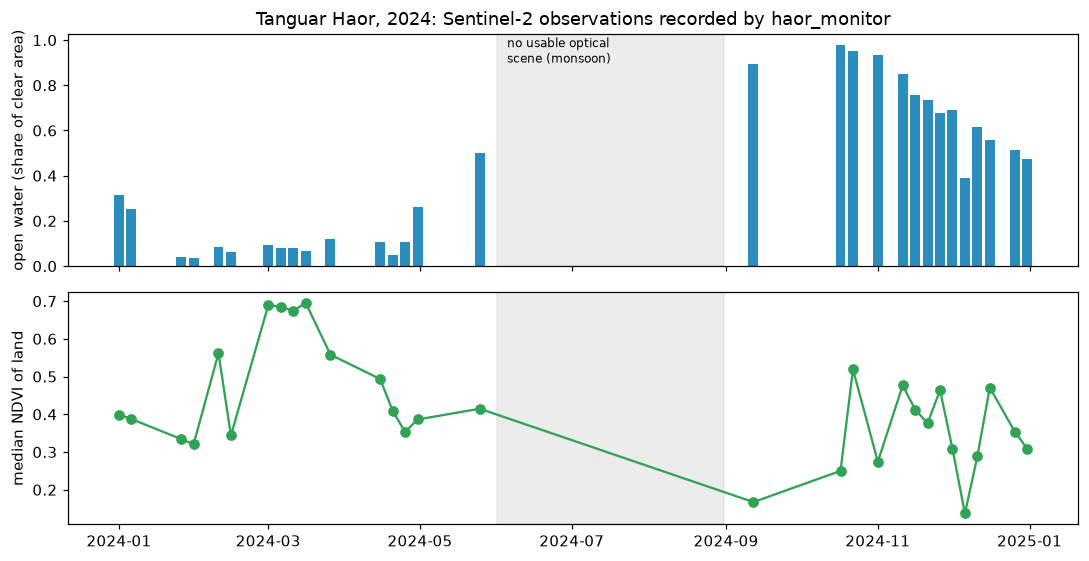

date,2024-01-01,2024-01-06,2024-01-26,2024-01-31,2024-02-10,2024-02-15,2024-03-01,2024-03-06,2024-03-11,2024-03-16,...,2024-11-11,2024-11-16,2024-11-21,2024-11-26,2024-12-01,2024-12-06,2024-12-11,2024-12-16,2024-12-26,2024-12-31
scenes,1.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,...,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
clear_fraction,1.000,1.000,0.366,0.655,0.987,0.542,0.964,0.970,0.979,0.989,...,0.904,1.000,0.624,0.959,0.999,0.395,0.999,0.999,0.999,1.000
water_fraction,0.313,0.252,0.039,0.036,0.084,0.063,0.095,0.081,0.081,0.068,...,0.849,0.758,0.733,0.676,0.690,0.390,0.615,0.558,0.515,0.474
ndvi_land_median,0.399,0.387,0.334,0.321,0.562,0.344,0.689,0.686,0.673,0.696,...,0.477,0.412,0.376,0.464,0.308,0.137,0.288,0.471,0.354,0.309


In [13]:
# Load observations and plot open water and land NDVI through 2024
obs = pd.read_parquet(data_dir / "observations.parquet")
ok = obs[obs["flags"] == ""]                       # obs["flags"], not obs.flags: DataFrame.flags is a pandas property
print(f"{len(obs)} observations, {len(ok)} usable; flagged: {obs.loc[obs['flags'] != '', ['date', 'flags']].astype(str).values.tolist()}")
fig, ax = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
ax[0].bar(ok.date, ok.water_fraction, width=4, color="#2b8cbe"); ax[0].set_ylabel("open water (share of clear area)")
ax[0].set_title("Tanguar Haor, 2024: Sentinel-2 observations recorded by haor_monitor")
ax[1].plot(ok.date, ok.ndvi_land_median, "o-", color="#31a354"); ax[1].set_ylabel("median NDVI of land")
for a in ax:
    a.axvspan(pd.Timestamp("2024-06-01"), pd.Timestamp("2024-08-31"), color="grey", alpha=0.15)
ax[0].text(pd.Timestamp("2024-06-05"), 0.9, "no usable optical\nscene (monsoon)", fontsize=8)
plt.tight_layout(); plt.show()
display(ok.set_index(ok.date.dt.strftime("%Y-%m-%d"))[["scenes", "clear_fraction", "water_fraction", "ndvi_land_median"]].round(3).T)


The 37 log records (3 run starts, 31 processed days, 3 run ends) are directly a table of run
history: durations, days found and processed, failures. In production the same JSON lines go to a
log service (CloudWatch, Cloud Logging, Loki), where an alert on `level = ERROR` or on a non-zero
exit code replaces watching the job.

The data quality flags removed one observation, 2 September 2024, when the haor was completely
cloud-covered.

The 30 usable observations trace the haor's year:

- **Dry season:** open water fell from 31% of the clear area on 1 January to 3.6% at the end of
  January.
- **Boro rice:** land NDVI peaked at 0.70 in mid-March.
- **Monsoon gap:** there is no usable optical observation from June to August.
- **Flood:** after the monsoon the haor was 97.7% water on 17 October, then drained to 47% by
  31 December.

The monsoon gap is the limit of optical monitoring here. Notebook 08_11 fills it with Sentinel-1
radar, which sees through cloud.

## Summary and exercises

**Key ideas**

- Put science in pure functions, input/output at the edges, and configuration in the environment.
- Tests that need no network run in seconds anywhere; quality gates make style and coverage automatic.
- CI runs the same checks on every change on a clean machine; a red build blocks a bad merge.
- Containers fix the environment; keep images small, pinned and non-root, and keep data and secrets out.
- Scheduled jobs must be idempotent (safe to repeat), observable (structured logs, exit codes) and
  write atomically; version their outputs.

**What we did**

- **The project:** a package (342 lines), tests (190 lines), a Dockerfile and two workflows.
- **Quality gates:** lint, format and 12 tests with 93% coverage, all passing; a deliberately broken
  offset rule was caught by a test in 1.3 s.
- **Git and CI:** git history for code and data; the CI workflow's checks run locally, green.
- **Container:** the Dockerfile passes 8 best-practice checks. It is built by CI; Docker is not
  available here.
- **Scheduled runs:** three simulated runs against Planetary Computer (16, 0 and 15 new days) gave a
  31-row table without duplicates, logged as JSON lines.
- **Science:** Tanguar Haor was 97.7% open water in October 2024 and 3.6% in January; Boro rice NDVI
  peaked at 0.70 in March.

**Exercises**

1. Add a test that fails if a day's `water_fraction` changes by more than 0.5 between consecutive
   usable observations, and decide whether that is a data error or a real event.
2. Add `HAOR_RESOLUTION=10` support to the CI matrix as a second configuration. What does it cost in run time?
3. Make the pipeline write a small STAC catalogue (one item per observation) next to the table.
4. Replace the GitHub Actions schedule with a Kubernetes `CronJob` manifest that runs the container image.
5. Send an alert (an issue, an email or a chat message) when the monitor workflow fails, using the
   job's failure status.

**References**

- Kim, G., Humble, J., Debois, P. & Willis, J. (2021). *The DevOps Handbook*, 2nd ed. IT Revolution.
- GitHub Actions documentation. https://docs.github.com/actions
- Docker best practices for building images. https://docs.docker.com/build/building/best-practices/
- pytest and ruff documentation. https://docs.pytest.org, https://docs.astral.sh/ruff/
- Ramsar Sites Information Service: Tanguar Haor (site no. 1031). https://rsis.ramsar.org